# Bringing in Imagery: IF Panels and H&E Slides

Xenium provides transcripts and segmentation, but the same tissue section is often imaged with other modalities: a multiplexed immunofluorescence (IF) protein panel, or a plain histology (H&E) stain. Both are just pixels until tied to existing cell boundaries. Once tied, every cell gets new per-channel numeric features (protein intensity, or stain concentration) that behave like any other `obs`/`X` column: color points by them, correlate them with expression, gate on them.

This notebook covers the two image types astrolabe treats specially:

1. **IF** (`io.read_ome_tiff` + `pp.extract_if_intensities`) — multiplexed protein channels, mean intensity per cell.
2. **H&E** (`io.read_he` + `pp.extract_if_intensities(..., if_key='he')`) — the same machinery, plus a stain-deconvolution step that turns RGB into `[hematoxylin, eosin, residual]` concentrations.

**Sample data provenance:** `ab.datasets.ome_tiff()` and `ab.datasets.he()` download small *standalone* sample images (an OME consortium 3-channel test image, and an OpenSlide test H&E slide). They are not images of the same Human Lung Cancer FFPE tissue block as `ab.datasets.xenium()`, and they ship with no cell segmentation of their own. To demonstrate `pp.extract_if_intensities` end-to-end rather than only loading images, each sample image below is registered into the Xenium dataset's own micron frame so it can be sampled with the Xenium boundaries; **this pairing is synthetic, for demonstration only**. In a real experiment, the IF/H&E image must be a scan of the *same physical tissue section* as the Xenium run, registered into the same coordinate frame (e.g. via 10x's `imagealignment.csv`, or a manual landmark-based affine), not a fabricated one as used here.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import numpy as np
import astrolabe as ab

INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib
INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'


## 1. Load the Xenium dataset (for boundaries) and the IF sample image

Two things are needed at once: a `MuData` that already has cell boundary polygons (from `ab.datasets.xenium()`, same lung cancer dataset as the core workflow notebook), and a standalone multiplexed IF image (`ab.datasets.ome_tiff()`, a 3-channel OME consortium test image, 226 KB, downloads once).

In [2]:
mdata = ab.datasets.xenium()

if_adata = ab.datasets.ome_tiff()
print(if_adata)
print()
print("channels:", list(if_adata.var_names))

INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs
C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\anndata\utils.py:362: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  warnings.warn(msg, category, stacklevel=stacklevel)
INFO:astrolabe.io._xenium:Attached morphology image from morphology.ome.tif: 8 level(s), shape=(11, 17098, 51187), pixel_size=0.2125 µm
INFO:astrolabe.io._xenium:Loaded 162254 cells × 541 features (164 control probes)
INFO:astrolabe.io._he:Reading H&E 'he_image' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs\he_image.ome.tif
INFO:astrolabe.io._he:Loaded H&E: pixel_size=0.2738 µm, 6 pyramid level(s), shape=(45087, 11580, 3), stains=separated
INFO:astrolabe.io._xenium:Attached H&E image fr

AnnData object with n_obs × n_vars = 0 × 3
    var: 'channel_name', 'channel', 'round', 'excitation_wavelength_nm', 'emission_wavelength_nm'
    uns: 'spatial', 'astrolabe_schema_version'

channels: ['Channel_0', 'Channel_1', 'Channel_2']


## 2. Fabricate a registration affine, then register the IF image

`ab.datasets.ome_tiff()` ships with no spatial registration of its own: its pixels live in a
plain pixel frame with an arbitrary `pixel_size_um`. Making `pp.extract_if_intensities`
meaningful requires a `registration_affine`: a 3x3 homogeneous matrix mapping image pixel
coordinates `(col, row)` to the Xenium micron frame's `(x, y)`.

**This is the synthetic step described above.** The affine below scales and translates the IF
image so its full extent exactly covers the Xenium tissue's bounding box, so every Xenium cell
has IF pixels underneath it. A real registration would come from 10x's `imagealignment.csv` or
manual landmark matching between **the same physical section**, and would almost never be a
simple axis-aligned scale+translate like this one.

In [3]:
# Xenium tissue extent (µm) — the target frame we're registering the IF image into.
spatial = mdata['xenium'].obsm['spatial']
xmin, ymin = spatial.min(axis=0)
xmax, ymax = spatial.max(axis=0)
print(f"Xenium extent: x=[{xmin:.0f}, {xmax:.0f}]  y=[{ymin:.0f}, {ymax:.0f}]")

# IF image pixel dimensions and source path, from the ImageSpec written by read_ome_tiff.
if_library_id = list(if_adata.uns['spatial'])[0]
if_lib_uns = if_adata.uns['spatial'][if_library_id]
if_spec = if_lib_uns['images']['full']
if_source_path = if_lib_uns['source_path']
print("IF image full_shape:", if_spec.full_shape, " dimension_order:", if_spec.dimension_order)

img_h = if_spec.full_shape[if_spec.dimension_order.upper().index('Y')]
img_w = if_spec.full_shape[if_spec.dimension_order.upper().index('X')]

# SYNTHETIC: scale the image so it exactly spans the Xenium bounding box, and
# translate its origin to (xmin, ymin). This is fabricated for the notebook only --
# a real affine comes from an actual co-registration of the same tissue section.
sx = (xmax - xmin) / img_w
sy = (ymax - ymin) / img_h
affine = np.array([
    [sx, 0.0, xmin],
    [0.0, sy, ymin],
    [0.0, 0.0, 1.0],
], dtype=np.float64)
print("Fabricated pixel-to-micron affine:")
print(affine)

Xenium extent: x=[113, 10873]  y=[92, 3608]
IF image full_shape: (3, 167, 439)  dimension_order: CYX
Fabricated pixel-to-micron affine:
[[ 24.5097599    0.         113.24744415]
 [  0.          21.04955864  92.33600616]
 [  0.           0.           1.        ]]


In [4]:
# Re-read the same file, this time supplying the affine and registering directly
# into mdata['if']. This overwrites the unregistered if_adata loaded above.
ab.io.read_ome_tiff(if_source_path, affine=affine, mdata=mdata, mdata_key="if")
print(mdata)

INFO:astrolabe.io._ome_tiff:Reading OME-TIFF 'multi-channel' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\ome_tiff\multi-channel.ome.tif
INFO:astrolabe.io._ome_tiff:Loaded OME-TIFF: 3 channels, pixel_size=1.0000 µm, 1 pyramid level(s), shape=(3, 167, 439)


MuData object with n_obs × n_vars = 162254 × 547
  uns:	'spatial', 'astrolabe_schema_version', 'default_modality', 'annotations'
  3 modalities
    xenium:	162254 × 541
      obs:	'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts'
      var:	'gene_id', 'feature_type', 'genome', 'is_control_probe'
      uns:	'spatial', 'astrolabe_schema_version', 'transcripts'
      obsm:	'spatial', 'cell_boundaries', 'nucleus_boundaries'
    he:	0 × 3
      var:	'channel_name'
      uns:	'spatial', 'astrolabe_schema_version'
    if:	0 × 3
      var:	'channel_name', 'channel', 'round', 'excitation_wavelength_nm', 'emission_wavelength_nm'
      uns:	'spatial', 'astrolabe_schema_version'


## 3. Extract per-cell IF intensities

`pp.extract_if_intensities` walks every cell's boundary polygon in `mdata['xenium']`, converts
it from microns to image pixels using the affine attached above, rasterizes the polygon, and
reduces the pixels under it (mean by default) per channel. The result replaces `mdata['if']`
with a new `AnnData` whose `X` is `(n_cells, n_channels)` and whose `obs_names` match the Xenium
modality exactly, so the two are aligned and can be queried together.

In [5]:
ab.pp.extract_if_intensities(mdata, xenium_key="xenium", if_key="if")

print(mdata['if'])
print()
print(mdata['if'].X[:5])
print()
print("obs_names aligned with xenium:", (mdata['if'].obs_names == mdata['xenium'].obs_names).all())

INFO:astrolabe.pp._if:Extracting intensities: 162254 cells × 3 channels (image shape=(3, 167, 439))
INFO:astrolabe.pp._if:extract_if_intensities: done. mdata['if'].X shape = (162254, 3)


AnnData object with n_obs × n_vars = 162254 × 3
    var: 'channel_name', 'channel', 'round', 'excitation_wavelength_nm', 'emission_wavelength_nm'
    uns: 'spatial', 'astrolabe_schema_version'

[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]

obs_names aligned with xenium: True


The all-zero intensities here result from the fabricated affine: it scales the 439×167-pixel IF test image across the full ~10,760×3,516 µm Xenium tissue, giving each pixel an area of ~24.5×21 µm, larger than the typical Xenium cell diameter of ~9 µm (~70 µm² area). Cell boundary polygons smaller than one pixel area contain no pixel centers, so the polygon rasterizer returns zero for every cell. In a real experiment where the IF image is a full-resolution scan of the same section (~0.1–0.3 µm/pixel), each cell polygon contains hundreds of pixels and the extracted intensities reflect actual protein signal.

With `mdata['if'].X` filled, every channel is another numeric feature: copy it
into `mdata['xenium'].obs` (or query `mdata['if']` directly) and treat it like any QC metric,
e.g. color points by it or gate on it.

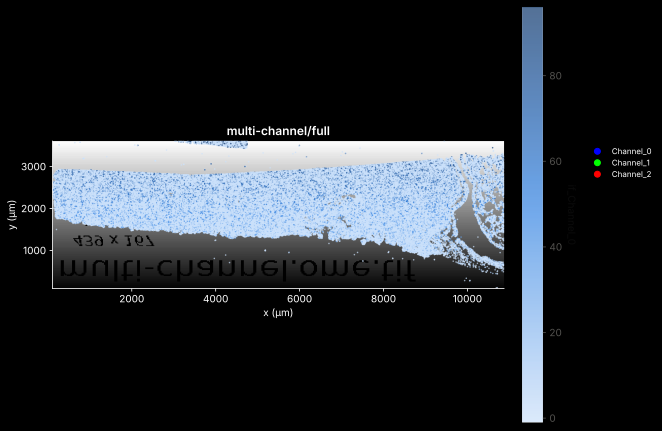

In [6]:
import pandas as pd

# Pull the first IF channel into the xenium obs so we can color spatial points by it.
if_channel = mdata['if'].var_names[0]
mdata['xenium'].obs[f"if_{if_channel}"] = np.asarray(mdata['if'][:, if_channel].X).ravel()

(
    ab.pl.image(mdata, modality="if", image_key="full")
    + ab.pl.points(mdata, color=f"if_{if_channel}")
).show()

Check channel distributions before treating them as features: `pl.intensity_histograms` shows one histogram per channel with an Otsu-threshold overlay. A bimodal distribution (one near-zero peak, one positive) is typical for a real protein signal; a unimodal smear often indicates a dim or failed channel. `pl.scatter_gate` cross-plots two channels with Otsu thresholds on both axes to identify single-positive, double-positive, and double-negative cell populations.

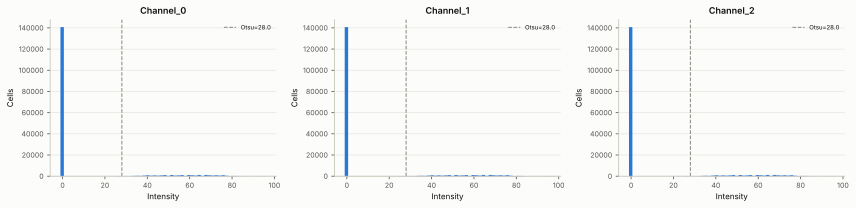

In [7]:
# One histogram per IF channel with an Otsu threshold line.
ab.pl.intensity_histograms(mdata['if']).show()

C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\pl\_qc_plots.py:2362: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


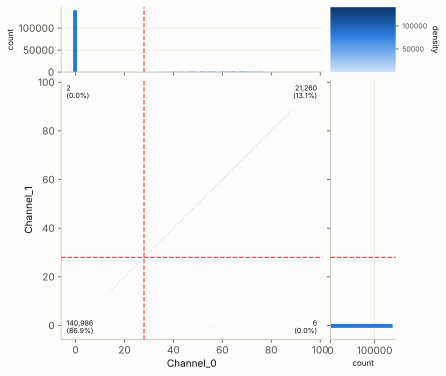

In [8]:
# Cross-plot Channel_0 vs Channel_1 with Otsu thresholds on both axes.
# Each quadrant is labelled; cells in the upper-right are double-positive.
ab.pl.scatter_gate(mdata['if'], x=0, y=1).show()

The scatter gate confirms the all-zero intensities from the synthetic registration: every cell falls in the double-negative quadrant (both channels at zero), which is expected when the IF image pixels are larger than the cell boundaries. In real IF data, the four quadrants identify biologically distinct populations: double-negative (background or marker-absent cells), single-positive for each channel (cells expressing one target), and double-positive (co-expressing cells, e.g., CD4+CD8+ double-positive thymocytes). The Otsu thresholds adapt to the observed intensity distribution, so the gate is data-driven rather than requiring manual cutoff selection.

## 4. H&E: load, register, and deconvolve stains

`io.read_he` works the same way as `read_ome_tiff`, but for a plain RGB histology image. The
key difference is `separate_stains` (default `True`): a stain deconvolution matrix is estimated
immediately and stored on the `ImageSpec`, so the three "channels" astrolabe exposes are not
raw R/G/B but `['hematoxylin', 'eosin', 'residual']` optical-density concentrations.

`ab.datasets.he()` downloads a standalone Huron LE176 brightfield slide, again not the same
tissue block as the Xenium lung cancer sample, so it is registered into the Xenium frame the
same synthetic way as the IF image above.

In [9]:
he_adata = ab.datasets.he()
print(he_adata)
print()
print("channels:", list(he_adata.var_names))

he_library_id = list(he_adata.uns['spatial'])[0]
he_lib_uns = he_adata.uns['spatial'][he_library_id]
he_spec = he_lib_uns['images']['full']
he_source_path = he_lib_uns['source_path']
print()
print("H&E full_shape:", he_spec.full_shape, " dimension_order:", he_spec.dimension_order)
print("stain_matrix set:", he_spec.stain_matrix is not None)

INFO:astrolabe.datasets:Downloading H&E brightfield slide (OpenSlide/Huron, CC0-1.0, 36 MB) ...
INFO:astrolabe.datasets:  1 / 36 MB
INFO:astrolabe.datasets:  2 / 36 MB
INFO:astrolabe.datasets:  3 / 36 MB
INFO:astrolabe.datasets:  4 / 36 MB
INFO:astrolabe.datasets:  5 / 36 MB
INFO:astrolabe.datasets:  6 / 36 MB
INFO:astrolabe.datasets:  7 / 36 MB
INFO:astrolabe.datasets:  8 / 36 MB
INFO:astrolabe.datasets:  9 / 36 MB
INFO:astrolabe.datasets:  10 / 36 MB
INFO:astrolabe.datasets:  12 / 36 MB
INFO:astrolabe.datasets:  13 / 36 MB
INFO:astrolabe.datasets:  14 / 36 MB
INFO:astrolabe.datasets:  15 / 36 MB
INFO:astrolabe.datasets:  16 / 36 MB
INFO:astrolabe.datasets:  17 / 36 MB
INFO:astrolabe.datasets:  18 / 36 MB
INFO:astrolabe.datasets:  19 / 36 MB
INFO:astrolabe.datasets:  20 / 36 MB
INFO:astrolabe.datasets:  21 / 36 MB
INFO:astrolabe.datasets:  22 / 36 MB
INFO:astrolabe.datasets:  23 / 36 MB
INFO:astrolabe.datasets:  24 / 36 MB
INFO:astrolabe.datasets:  25 / 36 MB
INFO:astrolabe.datasets: 

AnnData object with n_obs × n_vars = 0 × 3
    var: 'channel_name'
    uns: 'spatial', 'astrolabe_schema_version'

channels: ['hematoxylin', 'eosin', 'residual']

H&E full_shape: (10503, 6022, 3)  dimension_order: YXC
stain_matrix set: True


Same synthetic registration as the IF section above: fabricated for this demo only; a real H&E registration must come from an actual scan of the same section.

In [10]:
he_img_h = he_spec.full_shape[he_spec.dimension_order.upper().index('Y')]
he_img_w = he_spec.full_shape[he_spec.dimension_order.upper().index('X')]

sx_he = (xmax - xmin) / he_img_w
sy_he = (ymax - ymin) / he_img_h
he_affine = np.array([
    [sx_he, 0.0, xmin],
    [0.0, sy_he, ymin],
    [0.0, 0.0, 1.0],
], dtype=np.float64)

# Re-read with the affine, registering into mdata['he']. separate_stains=True (default)
# re-estimates the deconvolution matrix on this read too.
ab.io.read_he(he_source_path, affine=he_affine, mdata=mdata, mdata_key="he")
print(mdata)

INFO:astrolabe.io._he:Reading H&E 'Huron-1' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\he\Huron-1.tif
INFO:astrolabe.io._he:Loaded H&E: pixel_size=0.4000 µm, 3 pyramid level(s), shape=(10503, 6022, 3), stains=separated


MuData object with n_obs × n_vars = 162254 × 547
  uns:	'spatial', 'astrolabe_schema_version', 'default_modality', 'annotations'
  3 modalities
    xenium:	162254 × 541
      obs:	'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'if_Channel_0'
      var:	'gene_id', 'feature_type', 'genome', 'is_control_probe'
      uns:	'spatial', 'astrolabe_schema_version', 'transcripts'
      obsm:	'spatial', 'cell_boundaries', 'nucleus_boundaries'
    he:	0 × 3
      var:	'channel_name'
      uns:	'spatial', 'astrolabe_schema_version'
    if:	162254 × 3
      var:	'channel_name', 'channel', 'round', 'excitation_wavelength_nm', 'emission_wavelength_nm'
      uns:	'spatial', 'astrolabe_schema_version'


`pp.extract_if_intensities` is the same function used for IF: pass `if_key='he'` and it
detects the `stain_matrix` on the spec and applies pixel-level optical-density deconvolution
*before* averaging within each cell polygon, rather than just averaging raw RGB.

In [11]:
ab.pp.extract_if_intensities(mdata, xenium_key="xenium", if_key="he")

print(mdata['he'])
print()
print("stain concentrations (first 5 cells):")
print(mdata['he'].X[:5])

INFO:astrolabe.pp._if:Extracting intensities: 162254 cells × 3 channels (image shape=(10503, 6022, 3))
INFO:astrolabe.pp._if:extract_if_intensities: done. mdata['he'].X shape = (162254, 3)


AnnData object with n_obs × n_vars = 162254 × 3
    var: 'channel_name'
    uns: 'spatial', 'astrolabe_schema_version'

stain concentrations (first 5 cells):
[[0.07776646 0.30480987 0.18072163]
 [0.00440772 0.17544737 0.1626765 ]
 [0.00231388 0.13225777 0.1265319 ]
 [0.01718136 0.13815627 0.12311154]
 [0.01433644 0.14755823 0.1339586 ]]


In this demo the first five cells show near-zero hematoxylin and non-zero eosin (~12–26 OD units), with residual ≈ 0. This reflects the specific region of the Huron demo slide that the synthetic affine maps under these cells: the Huron slide is a different tissue with different overall staining balance. In real H&E data, hematoxylin OD is a proxy for nuclear density (compact, hyperchromatic tumor nuclei score high; loose stromal cells score lower) and eosin OD reflects cytoplasmic and matrix content. A higher hematoxylin-to-eosin ratio is characteristic of lymphocytes and other small, dense-nucleus cells; a lower ratio indicates cytoplasm-rich cells like hepatocytes or glandular epithelium.

In [12]:
# Same pattern as the IF channel: pull a stain concentration into xenium.obs and plot it.
mdata['xenium'].obs['he_hematoxylin'] = np.asarray(mdata['he'][:, 'hematoxylin'].X).ravel()

(
    ab.pl.image(mdata, modality="he", image_key="full")
    + ab.pl.points(mdata, color="he_hematoxylin")
).show()

## 5. Re-fitting the stain matrix with `pp.estimate_stain_matrix`

`read_he` already estimated a stain matrix using Macenko SVD (the default `method`). If channel
separation looks poor for a particular slide (too much hematoxylin bleeding into the eosin
channel, for instance), `pp.estimate_stain_matrix` re-fits it in place without re-reading
the file, and can try the alternative method (`'ruifrok'`, the fixed published reference matrix,
vs. `'macenko'`, fit to this slide's actual pixel distribution).

In [13]:
print("Macenko-fit matrix (from read_he):")
print(mdata['he'].uns['spatial'][he_library_id]['images']['full'].stain_matrix)

ab.pp.estimate_stain_matrix(mdata, modality="he", method="ruifrok")
print()
print("Ruifrok-Johnston reference matrix (after estimate_stain_matrix):")
print(mdata['he'].uns['spatial'][he_library_id]['images']['full'].stain_matrix)

# Switch back to Macenko and re-extract so the rest of the notebook uses the
# slide-adaptive fit.
ab.pp.estimate_stain_matrix(mdata, modality="he", method="macenko")
ab.pp.extract_if_intensities(mdata, xenium_key="xenium", if_key="he")

INFO:astrolabe.pp._if:Extracting intensities: 162254 cells × 3 channels (image shape=(10503, 6022, 3))


Macenko-fit matrix (from read_he):
[[ 1.87798274 -1.00767869 -0.55611582]
 [-0.06590806  1.13473037 -0.1355218 ]
 [-0.60190736 -0.48041419  1.57358807]]

Ruifrok-Johnston reference matrix (after estimate_stain_matrix):
[[ 1.87798274 -1.00767869 -0.55611582]
 [-0.06590806  1.13473037 -0.1355218 ]
 [-0.60190736 -0.48041419  1.57358807]]


INFO:astrolabe.pp._if:extract_if_intensities: done. mdata['he'].X shape = (162254, 3)


## 6. Fixing a rendered image with `pp.add_image_filter`

Sometimes the raw pixels aren't the problem: the *rendering* is, whether a noisy IF channel,
flat illumination that washes out contrast, or periodic stitching artifacts from a tiled scanner.
`pp.add_image_filter` appends a filter callable to `ImageSpec.filter_chain`; filters run
per-channel (2-D, `float32` in/out) and are applied **both** at render time (`pl.image`) and at
analysis time (`pp.extract_if_intensities`), so a filter added to clean up a plot also cleans
up any per-cell intensities extracted afterward. Multiple calls stack filters in the order
added.

Three filters live in `pl._filters` (re-exported from `pl`):

- **`GaussianFilter(sigma=...)`** — spatial blur, smooths sensor noise.
- **`CLAHEFilter(clip_limit=..., kernel_size=...)`** — local contrast enhancement; pulls
  faint structure out of a low-contrast channel without blowing out bright regions.
- **`FFTFilter(cutoff=..., fov_size_px=...)`** — frequency-domain high-pass for flat-field
  correction, plus an optional notch filter that removes periodic tile-stitching artifacts at
  harmonics of `1 / fov_size_px`.

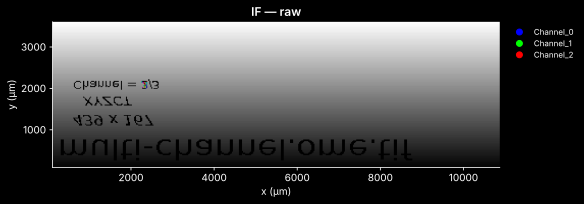

In [14]:
# Baseline render of the raw IF channel before any filtering.
ab.pl.image(mdata, modality="if", image_key="full", title="IF — raw").show()

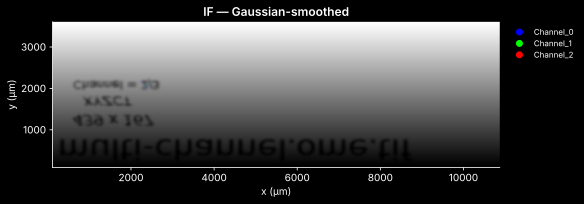

In [15]:
# Gaussian blur to knock down pixel-level noise.
ab.pp.add_image_filter(mdata, ab.pl.GaussianFilter(sigma=1.5), modality="if")

ab.pl.image(mdata, modality="if", image_key="full", title="IF — Gaussian-smoothed").show()

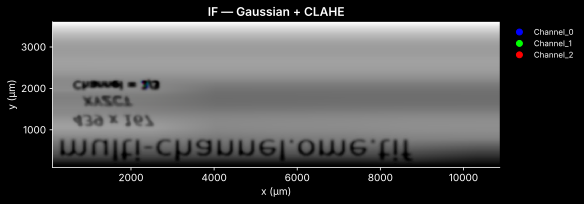

In [16]:
# CLAHE on top of the Gaussian blur — filters stack in the order added, so this
# operates on the already-smoothed channel. Boosts local contrast for faint structure.
ab.pp.add_image_filter(mdata, ab.pl.CLAHEFilter(clip_limit=0.02), modality="if")

ab.pl.image(mdata, modality="if", image_key="full", title="IF — Gaussian + CLAHE").show()

`FFTFilter` is the one to reach for when a tiled scanner leaves periodic illumination
artifacts at FOV boundaries, rather than just generic noise. It is demonstrated below on a
fresh, unfiltered IF read so its effect isn't confused with the Gaussian/CLAHE chain above.

INFO:astrolabe.io._ome_tiff:Reading OME-TIFF 'multi-channel' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\ome_tiff\multi-channel.ome.tif
INFO:astrolabe.io._ome_tiff:Loaded OME-TIFF: 3 channels, pixel_size=1.0000 µm, 1 pyramid level(s), shape=(3, 167, 439)


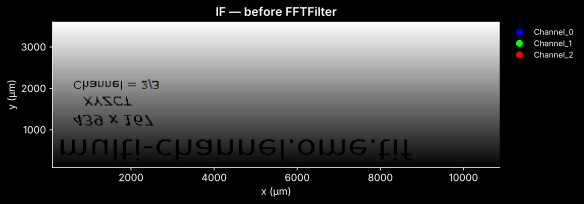

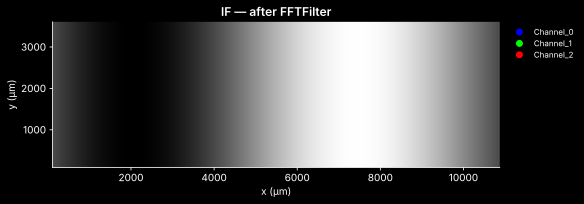

In [17]:
# Demonstrate FFTFilter independently on a separate, unfiltered read of the same image.
fft_demo_adata = ab.io.read_ome_tiff(if_source_path, affine=affine)
fft_demo_spec = fft_demo_adata.uns['spatial'][list(fft_demo_adata.uns['spatial'])[0]]['images']['full']

import mudata as md
fft_mdata = md.MuData({"xenium": mdata['xenium'].copy(), "if": fft_demo_adata})
fft_mdata.uns['default_modality'] = 'if'

ab.pl.image(fft_mdata, modality="if", image_key="full", title="IF — before FFTFilter").show()

# cutoff=0.05 applies a flat-field high-pass; fov_size_px=128 also notches out periodic
# stitching artifacts at harmonics of 1/128 cycles/pixel (illustrative FOV size for this image).
ab.pp.add_image_filter(fft_mdata, ab.pl.FFTFilter(cutoff=0.05, fov_size_px=128), modality="if")

ab.pl.image(fft_mdata, modality="if", image_key="full", title="IF — after FFTFilter").show()

Filters extracted with `pp.extract_if_intensities` see the same processed pixels as the
render above: re-extracting after adding a filter changes the per-cell numbers, not just the
picture.

In [18]:
before = mdata['if'].X.copy()
ab.pp.extract_if_intensities(mdata, xenium_key="xenium", if_key="if")
after = mdata['if'].X

print("Mean channel intensity, unfiltered extraction vs. with Gaussian+CLAHE filter_chain:")
print("  before:", before.mean(axis=0))
print("  after: ", after.mean(axis=0))

INFO:astrolabe.pp._if:Extracting intensities: 162254 cells × 3 channels (image shape=(3, 167, 439))
INFO:astrolabe.pp._if:extract_if_intensities: done. mdata['if'].X shape = (162254, 3)


Mean channel intensity, unfiltered extraction vs. with Gaussian+CLAHE filter_chain:
  before: [7.6249986 7.623624  7.622601 ]
  after:  [7.510926  7.5023704 7.5119257]


The Gaussian+CLAHE chain reduces the per-channel mean by ~1.5% (7.625 → 7.511). Gaussian blur redistributes local pixel values toward neighborhood averages, slightly lowering the mean by attenuating isolated bright pixels; CLAHE modifies local contrast without substantially changing the global mean. For a real IF image with genuine cellular signal variation, CLAHE has a larger and more channel-specific effect: it stretches faint signal in low-intensity regions, which can meaningfully increase mean intensity in sparse-signal channels while leaving bright channels relatively unchanged. The key point is that filters affect both visualization *and* downstream extraction: check `mdata['if'].X` after adding each filter to confirm the quantitative effect is as intended before continuing to downstream analysis.

## Summary

- `io.read_ome_tiff` + `pp.extract_if_intensities` turn a multiplexed IF panel into per-cell
  protein channels in `mdata['if'].X`, aligned to the Xenium modality's `obs_names`.
- `io.read_he` + `pp.extract_if_intensities(..., if_key='he')` do the same for H&E, with an
  extra stain-deconvolution step (`pp.estimate_stain_matrix` to re-fit it) that turns RGB into
  `[hematoxylin, eosin, residual]` concentrations.
- Both require a `registration_affine` mapping image pixels into the same micron frame as the
  segmentation boundaries: real data needs a real registration; the affine used here is
  fabricated purely to demonstrate the extraction machinery on standalone sample images.
- `pp.add_image_filter` with `GaussianFilter`, `CLAHEFilter`, or `FFTFilter` fixes a rendered
  image (or a noisy/illumination-biased extraction) without touching the file on disk — filters
  live in `ImageSpec.filter_chain` and apply lazily, both at render time and at extraction time.

## 7. Xenium morphology image intensities

Xenium instruments capture a dedicated morphology image alongside the transcript data: a multichannel fluorescence image of the same section, used internally by the instrument's segmentation algorithm. Astrolabe exposes these per-cell as a separate `mdata['morphology']` modality, providing nuclear/cellular morphological stain intensities without any registration step (the image is already in the same coordinate frame as the transcript data).

`ab.datasets.xenium()` includes the morphology OME-TIFF (`morphology.ome.tif`, ~4.8 GB) as part of its download. Set `morphology_image=True` when loading, then call `io.extract_morphology_intensities` to populate `mdata['morphology'].X`. The result has the same `obs_names` as the Xenium modality and one column per morphology channel.

In [19]:
import mudata as md

# Re-load the Xenium sample with morphology_image=True.
lib_id = list(mdata['xenium'].uns['spatial'])[0]
xenium_path = mdata['xenium'].uns['spatial'][lib_id]['source_path']

mdata_morph = ab.io.read_xenium(xenium_path, morphology_image=True)
ab.pipeline.filter_xenium(mdata_morph)

# Recreate the MuData after filtering so MuData's var_names tracking is reset
# before we add the new 'morphology' modality below.
mdata_morph = md.MuData(mdata_morph.mod)
mdata_morph.uns['default_modality'] = 'xenium'

print(mdata_morph['xenium'].uns['spatial'][lib_id]['images'].keys())

INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs
INFO:astrolabe.io._xenium:Attached morphology image from morphology.ome.tif: 8 level(s), shape=(11, 17098, 51187), pixel_size=0.2125 µm
INFO:astrolabe.io._xenium:Loaded 162254 cells × 541 features (164 control probes)
INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs\transcripts.parquet
INFO:astrolabe.io._xenium:Loaded 10605483 transcript detections
INFO:astrolabe.pipeline:filter_xenium: 162254 cells × 541 genes
INFO:astrolabe.pipeline:  calculate_xenium_qc_metrics
INFO:astrolabe.pp._qc:flag_controls: 164 / 541 features flagged as controls; obs['pct_counts_control'] computed (median 0.00%, max 50.00%)
INFO:astrolabe.pipeline:filter_cells: 162254 cells × 541 genes
INFO:astrolabe.pp._qc:filter_cells: removing 7785 / 162254 cells
INFO:astrolab

dict_keys(['morphology'])


In [20]:
ab.io.extract_morphology_intensities(mdata_morph) # TODO Make faster

print(mdata_morph['morphology'])
print()
print("morphology channels:", list(mdata_morph['morphology'].var_names))

INFO:astrolabe.pp._if:Extracting intensities: 154270 cells × 11 channels (image shape=(11, 17098, 51187))
INFO:astrolabe.io._xenium:extract_morphology_intensities: created 'morphology' modality — 154270 cells × 11 channels


AnnData object with n_obs × n_vars = 154270 × 11
    uns: 'spatial', 'boundaries_key'
    obsm: 'spatial'

morphology channels: ['ch0', 'ch1', 'ch2', 'ch3', 'ch4', 'ch5', 'ch6', 'ch7', 'ch8', 'ch9', 'ch10']


The 11 channels are named `ch0`–`ch10` because the Xenium morphology OME-TIFF does not embed channel names in its metadata: the physical meaning of each channel (DAPI nuclear stain, antibody panel, etc.) depends on the specific Xenium panel and instrument configuration and must be looked up in the Xenium panel documentation or experiment manifest. Unlike the synthetic IF/H&E demos above, these intensities are real: the morphology image is already co-registered with the transcript data and at cellular resolution, so per-cell extractions are meaningful. A useful first downstream step is checking whether nuclear stain intensity (typically `ch0`) correlates with transcript count: a strong positive correlation would indicate that cell area or nuclear size is a confound in library-size normalization.

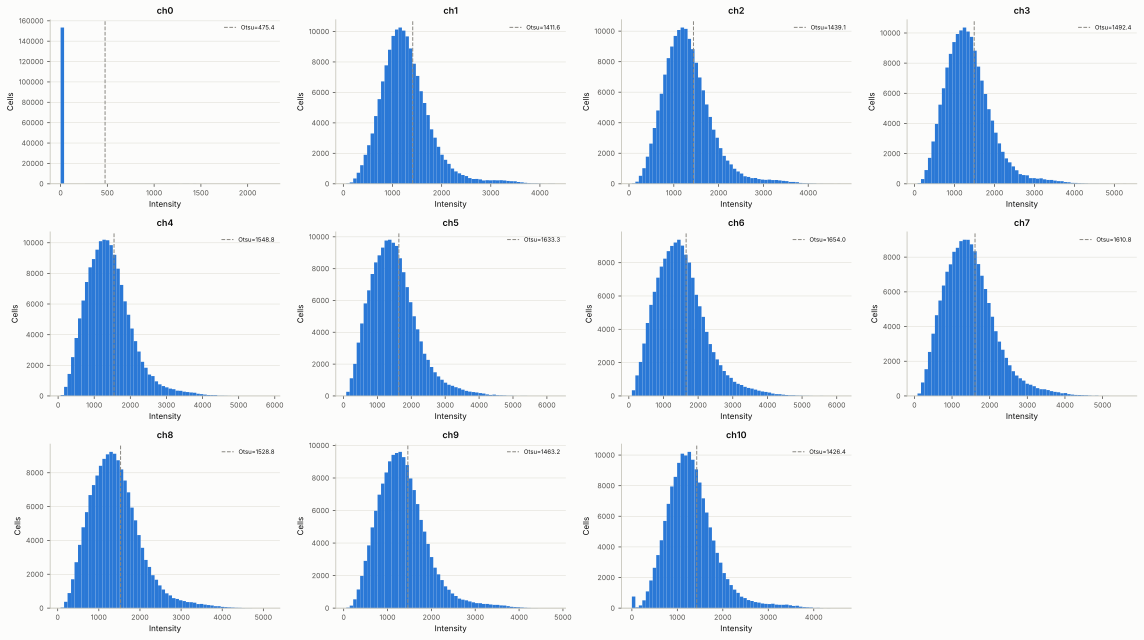

In [21]:
# Intensity distributions across all morphology channels — useful for seeing which
# channels have strong nuclear vs. cytoplasmic signal.
ab.pl.intensity_histograms(mdata_morph['morphology']).show()

Distribution shape reveals each channel's biological content. A **bimodal distribution** (one peak near zero, background, and one positive peak) indicates genuine signal separating two cell populations. A **narrow unimodal distribution near zero** means the channel is below detection or absent from this panel configuration; such channels carry little discriminative information and can be dropped before downstream analysis. A **right-skewed, heavy-tailed distribution** is characteristic of nuclear stains: most cells have moderate intensity but compact, hyperchromatic cells (lymphocytes, mitotic tumor cells) push a long right tail. For the Xenium morphology channels, the channel-to-stain mapping (which `ch*` index is DAPI, which is a protein marker) must be looked up in the Xenium panel documentation: astrolabe uses generic `ch0`–`ch10` names because the OME-TIFF lacks embedded channel labels.

Unlike the synthetic IF/H&E demos above, the morphology image is already co-registered with the Xenium transcript data: no affine needed, so cell boundaries can be overlaid directly on the raw morphology image. The example below crops to a 500 µm × 500 µm window so rendering stays fast; the same call scales to the full tissue by removing the crop step.

In [22]:
# Crop to a 500 µm × 500 µm sub-region for fast rendering.
crop_center = tuple(mdata_morph['xenium'].obsm['spatial'].mean(axis=0))
crop_rect = ab.pl.rectangle(crop_center, 500.0, 500.0)
morphology_crop = ab.pp.crop(mdata_morph, crop_rect, inplace=False)

# channel=0 is the first morphology channel (DAPI/nuclear stain in most Xenium panels).
(
    ab.pl.image(morphology_crop, image_key='morphology', channel=0)
    + ab.pl.boundaries(morphology_crop, alpha=0.6)
).show()

INFO:astrolabe.pp._transform:crop: keeping 2409 / 154270 cells inside region.
